In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [10]:
df = pd.read_csv("/content/6_class_csv.csv")
df.shape

(240, 7)

In [9]:
df.describe()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type
count,240.000000,240.000000,240.000000,240.000000,240.000000
mean,10497.462500,107188.361635,237.157781,4.382396,2.500000
std,9552.425037,179432.244940,517.155763,10.532512,1.711394
min,1939.000000,0.000080,0.008400,-11.920000,0.000000
25%,3344.250000,0.000865,0.102750,-6.232500,1.000000
50%,5776.000000,0.070500,0.762500,8.313000,2.500000
75%,15055.500000,198050.000000,42.750000,13.697500,4.000000
max,40000.000000,849420.000000,1948.500000,20.060000,5.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature (K)         240 non-null    int64  
 1   Luminosity(L/Lo)        240 non-null    float64
 2   Radius(R/Ro)            240 non-null    float64
 3   Absolute magnitude(Mv)  240 non-null    float64
 4   Star type               240 non-null    int64  
 5   Star color              240 non-null    object 
 6   Spectral Class          240 non-null    object 
dtypes: float64(3), int64(2), object(2)
memory usage: 13.3+ KB


In [14]:
X = df[['Temperature (K)', 'Luminosity(L/Lo)', 'Radius(R/Ro)', 'Absolute magnitude(Mv)']]
y = df['Star type']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
print(f"R^2 = {knn.score(X_test, y_test)}")

R^2 = 0.6875


In [15]:
from sklearn.metrics import classification_report
y_pred = knn.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.71      0.62      0.67         8
           1       0.67      0.75      0.71         8
           2       0.70      0.88      0.78         8
           3       0.71      0.62      0.67         8
           4       0.67      0.50      0.57         8
           5       0.67      0.75      0.71         8

    accuracy                           0.69        48
   macro avg       0.69      0.69      0.68        48
weighted avg       0.69      0.69      0.68        48



In [16]:
df.describe()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type
count,240.000000,240.000000,240.000000,240.000000,240.000000
mean,10497.462500,107188.361635,237.157781,4.382396,2.500000
std,9552.425037,179432.244940,517.155763,10.532512,1.711394
min,1939.000000,0.000080,0.008400,-11.920000,0.000000
25%,3344.250000,0.000865,0.102750,-6.232500,1.000000
50%,5776.000000,0.070500,0.762500,8.313000,2.500000
75%,15055.500000,198050.000000,42.750000,13.697500,4.000000
max,40000.000000,849420.000000,1948.500000,20.060000,5.000000


In [18]:
# Kerakli kutubxonalarni import qilamiz
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# StandardScaler yordamida standartlashtirish (o'rtacha qiymat = 0, standart og'ish = 1)
# va KNN modelini ketma-ket bajaradigan Pipeline (konveyer) tuzamiz
pipe = Pipeline([
    ('sc', StandardScaler()),                      # 1-qadam: Ma'lumotlarni standart shkalaga keltirish
    ('knn', KNeighborsClassifier(n_neighbors=5))  # 2-qadam: KNN modelini sozlash (qo'shnilar soni = 5)
])

# Modelni o'quv ma'lumotlari (X_train, y_train) orqali o'qitamiz
pipe.fit(X_train, y_train)

# Test ma'lumotlaridagi aniqlik darajasini (R^2 skorini) hisoblaymiz
print(f"R^2 = {pipe.score(X_test, y_test)}")

R^2 = 0.9583333333333334


In [19]:
# Kerakli kutubxonalarni import qilamiz
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline

# MinMaxScaler (qiymatlarni 0 va 1 oralig'iga siqish)
# va KNN modelini ketma-ket bajaruvchi yangi Pipeline yaratamiz
min_max_pipe = Pipeline([
    ('scaler', MinMaxScaler()),                    # 1-qadam: Ma'lumotlarni 0 va 1 oralig'ida normallashtirish
    ('knn', KNeighborsClassifier(n_neighbors=5))  # 2-qadam: KNN modelini sozlash
])

# Modelni o'quv ma'lumotlariga moslab o'qitamiz
min_max_pipe.fit(X_train, y_train)

# Test ma'lumotlarida modelning aniqlik (R^2) ko'rsatkichini aniqlaymiz
min_max_score = min_max_pipe.score(X_test, y_test)
print(f"MinMaxScaler bilan model aniqligi (R^2): {min_max_score:.4f}")

MinMaxScaler bilan model aniqligi (R^2): 0.9583


In [21]:
# Kerakli kutubxonalarni import qilamiz
from sklearn.preprocessing import RobustScaler

# RobustScaler (chetga chiquvchi outlier qiymatlarga nisbatan chidamli, median va IQR asosida ishlaydi)
# va KNN modelini ketma-ket bajaruvchi Pipeline yaratamiz
pipe = Pipeline([
    ('sc', RobustScaler()),                        # 1-qadam: Chetga chiquvchi qiymatlarga chidamli masshtablash
    ('knn', KNeighborsClassifier(n_neighbors=5))  # 2-qadam: KNN modelini sozlash
])

# Modelni o'quv ma'lumotlari asosida o'qitamiz
pipe.fit(X_train, y_train)

# Test ma'lumotlari orqali olingan yakuniy aniqlik natijasini chiqaramiz
print(f"R^2 = {pipe.score(X_test, y_test)}")

R^2 = 0.9791666666666666


In [22]:
# Faqat ikkita ustunni ajratib olamiz
X_two_cols = df[['Temperature (K)', 'Radius(R/Ro)']]
y_two_cols = df['Star type']

# Ma'lumotlarni o'quv va test to'plamlariga ajratamiz (80/20 proportsiyada)
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X_two_cols, y_two_cols, test_size=0.2, random_state=42, stratify=y_two_cols
)

# Hech qanday scalersiz to'g'ridan-to'g'ri KNN modelini yaratamiz va o'qitamiz
knn_no_scale = KNeighborsClassifier(n_neighbors=5)
knn_no_scale.fit(X_train_2, y_train_2)

# Model aniqligini tekshiramiz
score_no_scale = knn_no_scale.score(X_test_2, y_test_2)
print(f"Faqat 2 ta ustun bilan (scalingsiz) KNN aniqligi: {score_no_scale:.4f}")

Faqat 2 ta ustun bilan (scalingsiz) KNN aniqligi: 0.5417


In [23]:
# StandardScaler va KNN modelini Pipeline yordamida birlashtiramiz
pipe_two_cols = Pipeline([
    ('sc', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

# Modelni faqat 2 ta ustunli ma'lumotlar bilan o'qitamiz
pipe_two_cols.fit(X_train_2, y_train_2)

# Model aniqligini tekshiramiz
score_two_cols_scaled = pipe_two_cols.score(X_test_2, y_test_2)
print(f"Faqat 2 ta ustun va StandardScaler bilan KNN aniqligi: {score_two_cols_scaled:.4f}")

Faqat 2 ta ustun va StandardScaler bilan KNN aniqligi: 0.6875


In [34]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

# 5 qismli kross-validatsiya sozlamasi
cv = StratifiedKFold(5, shuffle=True, random_state=42)
natija = []

# k ning turli toq qiymatlari uchun modelni tekshiramiz
for k in range(1, 42, 2):
    p = Pipeline([
        ('sc', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    # Kross-validatsiya ballarining o'rtacha qiymatini hisoblaymiz
    ball = cross_val_score(p, X_train, y_train, cv=cv).mean()
    # Natijani oddiy float ko'rinishida saqlaymiz
    natija.append((k, float(round(ball, 4))))
    print(f"k = {k} | score = {round(ball, 4)}")

# Eng yuqori ball bergan eng yaxshi k qiymatini topamiz
eng_yaxshi_k = max(natija, key=lambda t: t[1])
print(f"Eng yaxshi k va uning aniqligi: {eng_yaxshi_k}")

k = 1 | score = 0.9895
k = 3 | score = 0.9789
k = 5 | score = 0.9895
k = 7 | score = 0.9842
k = 9 | score = 0.9738
k = 11 | score = 0.9686
k = 13 | score = 0.9738
k = 15 | score = 0.9634
k = 17 | score = 0.9424
k = 19 | score = 0.9266
k = 21 | score = 0.9267
k = 23 | score = 0.9165
k = 25 | score = 0.8692
k = 27 | score = 0.8641
k = 29 | score = 0.8642
k = 31 | score = 0.8486
k = 33 | score = 0.8538
k = 35 | score = 0.8489
k = 37 | score = 0.8383
k = 39 | score = 0.8227
k = 41 | score = 0.8227
Eng yaxshi k va uning aniqligi: (1, 0.9895)


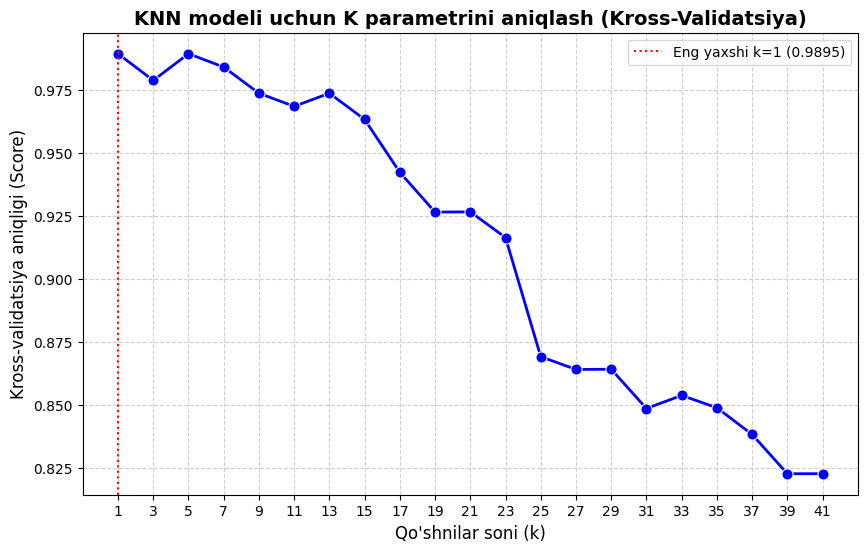

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Natijalardan k qiymatlari va mos keluvchi aniqlik ballarini ajratib olamiz
k_qiymatlari = [t[0] for t in natija]
ballar = [t[1] for t in natija]

# Grafik o'lchamini sozlaymiz
plt.figure(figsize=(10, 6))

# Chiziqli grafik chizamiz
sns.lineplot(x=k_qiymatlari, y=ballar, marker='o', color='b', linewidth=2, markersize=8)

# Grafik sarlavhasi va o'q nomlarini o'zbek tilida yozamiz
plt.title("KNN modeli uchun K parametrini aniqlash (Kross-Validatsiya)", fontsize=14, fontweight='bold')
plt.xlabel("Qo'shnilar soni (k)", fontsize=12)
plt.ylabel("Kross-validatsiya aniqligi (Score)", fontsize=12)

# Grafik tarmog'ini yoqamiz
plt.grid(True, linestyle='--', alpha=0.6)

# Eng yaxshi k qiymatini grafikda belgilaymiz
eng_yaxshi_k_qiymat = eng_yaxshi_k[0]
eng_yaxshi_ball = eng_yaxshi_k[1]
plt.axvline(x=eng_yaxshi_k_qiymat, color='r', linestyle=':', label=f"Eng yaxshi k={eng_yaxshi_k_qiymat} ({eng_yaxshi_ball})")
plt.legend()

# k o'qidagi sonlarni har birini ko'rsatamiz
plt.xticks(k_qiymatlari)

plt.show()

In [37]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Pipeline yaratish
pipe = Pipeline([
    ('sc', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# Giperparametrlar to'ri
grid = {
    'knn__n_neighbors': [1, 3, 5, 7, 9, 11, 15, 21],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}

# GridSearchCV ni sozlash va o'qitish (n_jobs=-1 barcha protsessor yadrolarini ishlatib, jarayonni tezlashtiradi)
gs = GridSearchCV(pipe, grid, cv=5, n_jobs=-1)
gs.fit(X_train, y_train)

print("Eng yaxshi parametrlar:", gs.best_params_)
print("Eng yaxshi natija (CV score):", gs.best_score_)

Eng yaxshi parametrlar: {'knn__metric': 'euclidean', 'knn__n_neighbors': 5, 'knn__weights': 'uniform'}
Eng yaxshi natija (CV score): 0.9948717948717949
